In [1]:
import time
import h5py
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
%matplotlib widget 

In [2]:
base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'


bgrun = 86 #shift2
# bgrun = 86 #shift3
# bgrun = 191 #shift4

# runs = [112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141,145]
runs = [112,114,115,116,118,138]
runs = [178,179,180,181,182,183,184,185,186,188,226,227,228,233,234,235,236,237,238,248,249,250]
runs = [112,113,114,115,116,117,118,119,120,121,122,123,127,140,141,142,145]
exp = 'rix101231825'


fyaml = '../roi_input.yml'

bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
bgyaml = '../BGroi_input.yml'

avg = Average(runs, proc_path = 'proc/Run', avg = 'mean', output_path = f'avg/{runs[0]}_to_{runs[-1]}.h5',
             raw_path = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run' , bgpath = bgname, fyaml=fyaml, bgyaml=bgyaml, 
             save= True,norm = True)

# avg.plot_svls2D(figsize=(12,4),savefig=True)
# avg.plot_svls2D_ET(figsize=(12,4),savefig=False)
# avg.plot_svls1D(figsize=(12,4))

[222. 415. 411. 422. 448. 407. 427. 419. 416. 424. 411. 421. 413. 424.
 438. 396. 427. 412. 406. 418. 424. 396. 410. 426. 408. 393. 407. 417.
 408. 407. 384. 415. 404. 401. 390.]
[715. 835. 826. 843. 882. 835. 830. 847. 837. 840. 824. 849. 839. 837.
 871. 799. 849. 826. 810. 850. 835. 794. 823. 845. 816. 782. 828. 816.
 830. 802. 784. 827. 805. 798. 778.]
[1184. 1257. 1244. 1271. 1318. 1245. 1245. 1278. 1249. 1248. 1261. 1265.
 1270. 1256. 1285. 1205. 1262. 1248. 1231. 1261. 1244. 1209. 1240. 1245.
 1214. 1199. 1248. 1214. 1225. 1233. 1169. 1232. 1203. 1201. 1181.]
[1520. 1687. 1678. 1692. 1743. 1661. 1659. 1696. 1678. 1659. 1694. 1693.
 1677. 1676. 1714. 1595. 1690. 1664. 1646. 1689. 1651. 1608. 1654. 1660.
 1622. 1592. 1659. 1634. 1628. 1642. 1549. 1649. 1606. 1594. 1599.]
[1872. 2116. 2090. 2106. 2186. 2081. 2066. 2124. 2092. 2093. 2110. 2120.
 2096. 2086. 2136. 1996. 2117. 2085. 2055. 2100. 2061. 2034. 2051. 2061.
 2044. 1994. 2069. 2040. 2032. 2058. 1941. 2039. 2032. 1983. 1998.]


In [5]:
import h5py, numpy as np, matplotlib.pyplot as plt

runs = [112,114,115,116,117,118,119,120,121,122,123,127,138,139,140,141,142,145]  # 138 dropped
proc = './proc/'

# reference peaks and their TRUE energies (set these to literature/elastic values)
PEAKS = {700.4: (699.8, 701.4),     # (target_eV): (window_lo, window_hi)
         704.5: (703.8, 705.6)}

def centroid(x, p, lo, hi):
    m = (x > lo) & (x < hi)
    return np.nansum(x[m]*p[m]) / np.nansum(p[m]) if np.nansum(p[m]) > 0 else np.nan

# measure both peaks per run (use OFF = ground state, cleanest reference)
cens = {pk: [] for pk in PEAKS}
data = {}
for r in runs:
    with h5py.File(f'{proc}Run{r:04d}.h5','r') as f:
        x   = np.asarray(f['scanvar_off'][()]).squeeze()
        pof = np.nansum(np.asarray(f['axis_svls_off_mean'][()]), 1)
    data[r] = x
    for pk,(lo,hi) in PEAKS.items():
        cens[pk].append(centroid(x, pof, lo, hi))

# --- diagnostic: do the two peaks drift together (offset) or apart (stretch)? ---
c1 = np.array(cens[700.4]); c2 = np.array(cens[704.5])
print('700-peak spread:', np.ptp(c1)*1000, 'meV')
print('705-peak spread:', np.ptp(c2)*1000, 'meV')
print('correlation of the two drifts:', np.corrcoef(c1[np.isfinite(c1)&np.isfinite(c2)],
                                                     c2[np.isfinite(c1)&np.isfinite(c2)])[0,1])
print('Δ(705-centroid)-Δ(700-centroid) per run, std:',
      np.nanstd((c2-np.nanmedian(c2)) - (c1-np.nanmedian(c1)))*1000, 'meV')

700-peak spread: 178.955078125 meV
705-peak spread: 78.67431640625 meV
correlation of the two drifts: 0.9474432211191866
Δ(705-centroid)-Δ(700-centroid) per run, std: 27.079861611127853 meV


In [6]:
TARGET700, TARGET705 = 700.4, 704.5
c1 = np.array(cens[700.4]); c2 = np.array(cens[704.5])

# per-run rigid shift = average of what each peak needs (minimizes max residual)
shifts = {}
for i, r in enumerate(runs):
    s1 = TARGET700 - c1[i]
    s2 = TARGET705 - c2[i]
    shifts[r] = np.nanmean([s1, s2])     # single offset, no slope
    print(f'run {r}: shift={shifts[r]*1000:+.0f} meV  '
          f'(resid@700={(s1-shifts[r])*1000:+.0f}, resid@705={(s2-shifts[r])*1000:+.0f} meV)')

common = np.linspace(696.5, 710.5, 36)
def regrid(r, key):
    with h5py.File(f'./proc/Run{r:04d}.h5','r') as f:
        xkey = 'scanvar_off' if 'off' in key else 'scanvar_on'
        x = np.asarray(f[xkey][()]).squeeze() + shifts[r]      # rigid shift only
        y = np.asarray(f[key][()])
    out = np.full((len(common), y.shape[1]), np.nan)
    for j in range(y.shape[1]):
        out[:, j] = np.interp(common, x, y[:, j], left=np.nan, right=np.nan)
    return out

run 112: shift=-45 meV  (resid@700=+72, resid@705=-72 meV)
run 114: shift=-60 meV  (resid@700=+58, resid@705=-58 meV)
run 115: shift=-71 meV  (resid@700=+52, resid@705=-52 meV)
run 116: shift=-88 meV  (resid@700=+47, resid@705=-47 meV)
run 117: shift=-103 meV  (resid@700=+36, resid@705=-36 meV)
run 118: shift=-120 meV  (resid@700=+31, resid@705=-31 meV)
run 119: shift=-118 meV  (resid@700=+41, resid@705=-41 meV)
run 120: shift=-137 meV  (resid@700=+36, resid@705=-36 meV)
run 121: shift=-159 meV  (resid@700=+25, resid@705=-25 meV)
run 122: shift=-171 meV  (resid@700=+20, resid@705=-20 meV)
run 123: shift=-174 meV  (resid@700=+22, resid@705=-22 meV)
run 127: shift=-127 meV  (resid@700=+24, resid@705=-24 meV)
run 138: shift=-129 meV  (resid@700=+28, resid@705=-28 meV)
run 139: shift=-134 meV  (resid@700=+23, resid@705=-23 meV)
run 140: shift=-132 meV  (resid@700=+31, resid@705=-31 meV)
run 141: shift=-146 meV  (resid@700=+27, resid@705=-27 meV)
run 142: shift=-141 meV  (resid@700=+32, res

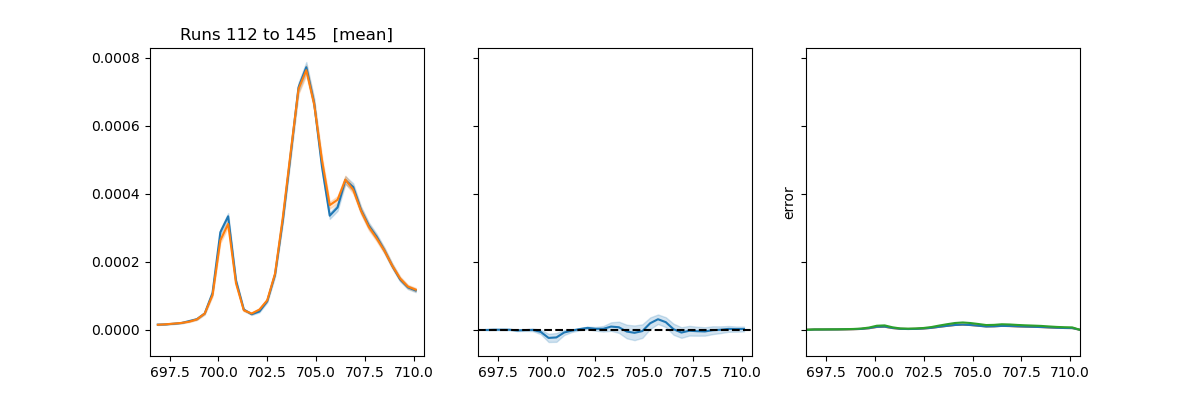

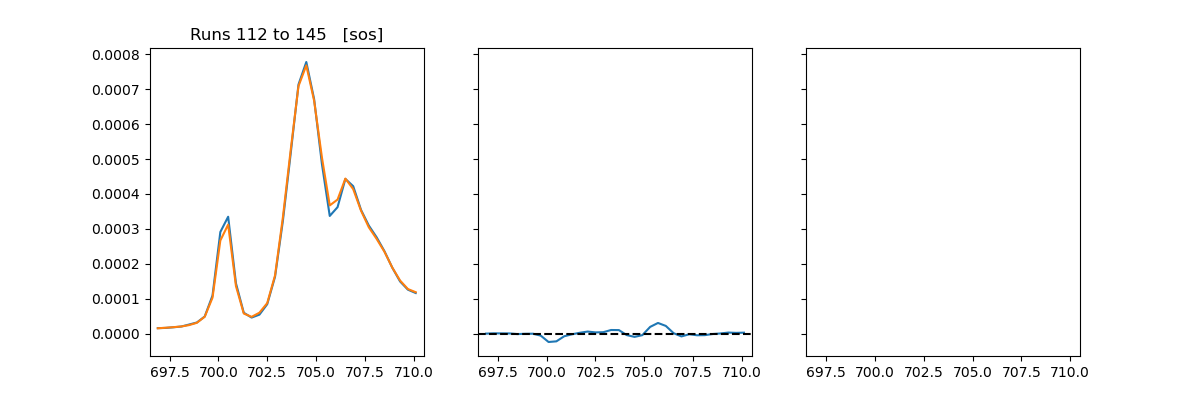

In [7]:
def regrid(r, key):
    with h5py.File(f'./proc/Run{r:04d}.h5','r') as f:
        xkey = 'scanvar_off' if 'off' in key else 'scanvar_on'
        x = np.asarray(f[xkey][()]).squeeze() + shifts[r]
        y = np.asarray(f[key][()])
    y2 = y[:, None] if y.ndim == 1 else y
    out = np.full((len(common), y2.shape[1]), np.nan)
    for j in range(y2.shape[1]):
        out[:, j] = np.interp(common, x, y2[:, j], left=np.nan, right=np.nan)
    return out.squeeze() if y.ndim == 1 else out

# ---- then the SoS build loop immediately below, same cell ----
mean_keys = ['axis_svls_on_mean','axis_svls_off_mean',
             'axis_svls_on_std','axis_svls_off_std']
sos_keys  = ['axis_svls_on_sumSV','axis_svls_off_sumSV',
             'axis_svls_on_sumI0','axis_svls_off_sumI0']
acc, wsum = {}, {'on': np.zeros(len(common)), 'off': np.zeros(len(common))}
for r in runs:
    with h5py.File(f'./proc/Run{r:04d}.h5','r') as f:
        co = np.asarray(f['counts_on'][()]).squeeze()
        cf = np.asarray(f['counts_off'][()]).squeeze()
        xon  = np.asarray(f['scanvar_on'][()]).squeeze()  + shifts[r]
        xoff = np.asarray(f['scanvar_off'][()]).squeeze() + shifts[r]
    co_c = np.interp(common, xon,  co, left=0, right=0)
    cf_c = np.interp(common, xoff, cf, left=0, right=0)
    for k in mean_keys:
        lab = 'on' if 'on' in k else 'off'
        m = np.nan_to_num(regrid(r, k), nan=0.0)
        w = (co_c if lab=='on' else cf_c)[:, None]
        if k not in acc: acc[k] = np.zeros_like(m)
        acc[k] += m * w
    for k in sos_keys:
        m = np.nan_to_num(regrid(r, k), nan=0.0)
        if k not in acc: acc[k] = np.zeros_like(m)
        acc[k] += m
    wsum['on'] += co_c; wsum['off'] += cf_c

aligned = {}
for k in mean_keys:
    lab = 'on' if 'on' in k else 'off'; w = wsum[lab][:, None]
    aligned[k] = np.divide(acc[k], w, out=np.full_like(acc[k], np.nan), where=w>0)
for k in sos_keys:
    aligned[k] = acc[k]

def _sos_pfy(sumSV, sumI0):
    sumI0 = sumI0.squeeze()
    num = np.nansum(sumSV, axis=1)
    return np.divide(num, sumI0, out=np.full_like(num, np.nan), where=sumI0>0)
aligned['PFY_on_sos']  = _sos_pfy(aligned['axis_svls_on_sumSV'],  aligned['axis_svls_on_sumI0'])
aligned['PFY_off_sos'] = _sos_pfy(aligned['axis_svls_off_sumSV'], aligned['axis_svls_off_sumI0'])
aligned['scanvar_on']=common; aligned['scanvar_off']=common
aligned['counts_on']=wsum['on']; aligned['counts_off']=wsum['off']

avg.average.update(aligned)
avg.get_PFYs(); avg.average['E_emi'] = avg.get_emi()
avg.plot_svls1D(figsize=(12,4), mode='mean')
avg.plot_svls1D(figsize=(12,4), mode='sos')

Plot SNR across runs, select "off","on","diff" mode when needed


=== 1 runs (mode=diff): just added 112 → [112] ===
[222. 415. 411. 422. 448. 407. 427. 419. 416. 424. 411. 421. 413. 424.
 438. 396. 427. 412. 406. 418. 424. 396. 410. 426. 408. 393. 407. 417.
 408. 407. 384. 415. 404. 401. 390.]
  despeckle [axis_svls_off_mean]: kernel=3, n_sigma=7 -> flagged 52 pixels (0.187%)
  despeckle [axis_svls_on_mean]: kernel=3, n_sigma=7 -> flagged 65 pixels (0.233%)
  despeckle TOTAL: 117 pixels across 2 map(s)
saving data in ./avg/Run0112to0112.h5
dict_keys(['axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_off_sumI0', 'axis_svls_off_sumSV', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'axis_svls_on_sumI0', 'axis_svls_on_sumSV', 'counts_off', 'counts_on', 'scanvar_off', 'scanvar_on', 'axis_svls_on_norm', 'axis_svls_off_norm', 'PFY_on_sos', 'PFY_off_sos', 'PFY_on_mean', 'PFY_on_std', 'PFY_off_mean', 'PFY_off_std'])
  |signal|=2.350e-05   noise=9.247e-06   SNR=2.542

=== 2 runs (mode=diff): just added 113 → [112, 113]

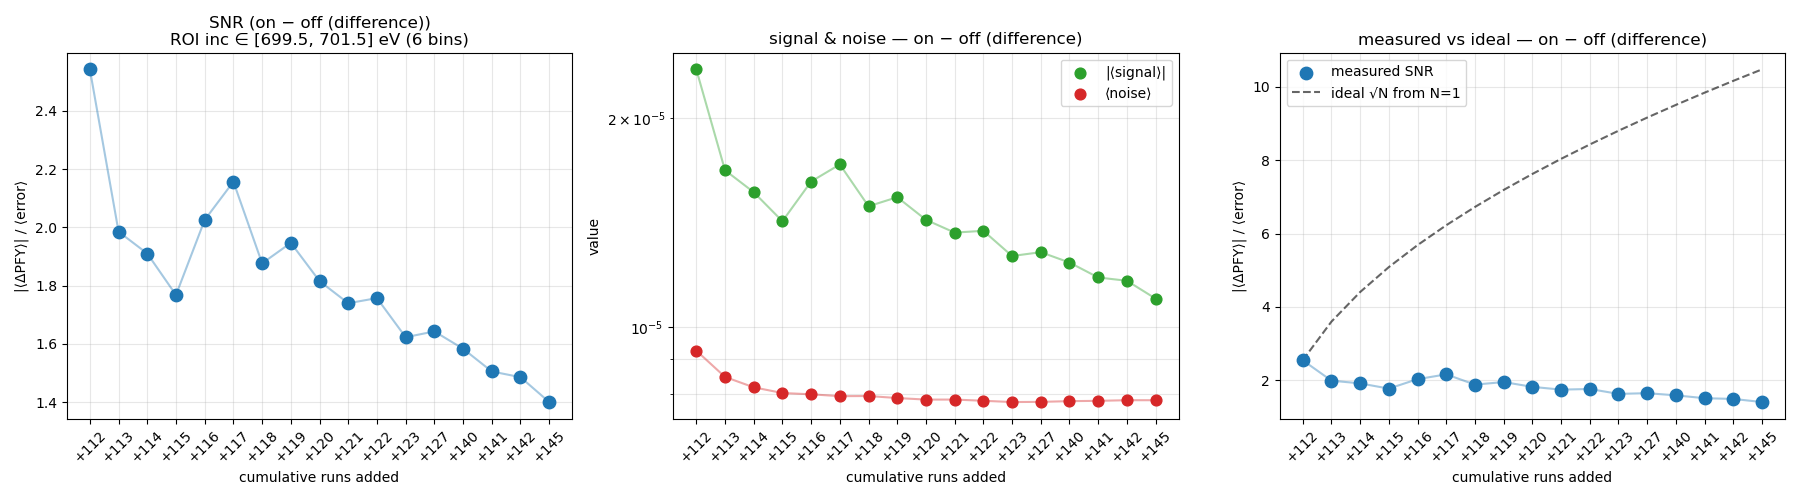


=== Per-run SNR changes (mode = diff) ===
step  new run        SNR      ΔSNR
1     112          2.542         -
2     113          1.985    -0.557  ✗
3     114          1.910    -0.075  ✗
4     115          1.768    -0.142  ✗
5     116          2.026    +0.258
6     117          2.157    +0.131
7     118          1.876    -0.280  ✗
8     119          1.947    +0.070
9     120          1.816    -0.131  ✗
10    121          1.740    -0.076  ✗
11    122          1.757    +0.017
12    123          1.623    -0.134  ✗
13    127          1.643    +0.020
14    140          1.584    -0.059  ✗
15    141          1.506    -0.078  ✗
16    142          1.486    -0.020  ✗
17    145          1.401    -0.085  ✗


In [6]:
base_folder = '/sdf/data/lcls/ds/rix/'
exp = 'rix101231825'
bgrun = 86
fyaml = '../roi_input.yml'
bgyaml = '../BGroi_input.yml'
bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'

runs = [112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141]
runs = [112,114,115,116,118,138]
runs = [178,179,180,181,182,183,184,185,186,188,226,227,228,233,234,235,236,237,238,248,249,250]
runs = [112,113,114,115,116,117,118,119,120,121,122,123,127,140,141,142,145]
# Incident-energy ROI around the feature of interest (A-peak GSB)
inc_roi = (699.5, 701.5)   # eV — adjust to bracket the feature in your data

# Which signal to evaluate: 'diff', 'off', or 'on'
mode = 'diff'

os.makedirs('avg', exist_ok=True)

# === Compute SNR for one subset, in the chosen mode ===
def compute_snr(runs_subset, inc_roi, mode):
    """
    Run Average over a subset, return SNR in the ROI for the chosen mode.
    
    mode='diff' -> |mean(PFY_on - PFY_off)| / mean(sqrt(std_on^2 + std_off^2))
    mode='off'  -> mean(PFY_off) / mean(PFY_off_std)
    mode='on'   -> mean(PFY_on)  / mean(PFY_on_std)
    """
    if mode not in ('diff', 'off', 'on'):
        raise ValueError(f"mode must be 'diff', 'off', or 'on', got {mode!r}")

    avg = Average(runs_subset, proc_path='proc/Run', avg='mean',
                  output_path=f'avg/cumulative_{len(runs_subset)}.h5',
                  raw_path=f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run',
                  bgpath=bgname, fyaml=fyaml, bgyaml=bgyaml,
                  save=True, norm=True)
    a = avg.average
    if 'PFY_on_mean' not in a:
        avg.get_PFYs()
        a = avg.average

    # ROI mask uses scanvar_off (same as scanvar_on, just pick one)
    inc = np.asarray(a['scanvar_off'])
    mask = (inc >= inc_roi[0]) & (inc <= inc_roi[1])
    if mask.sum() == 0:
        raise ValueError(f'No incident-energy bins in ROI {inc_roi}')

    if mode == 'diff':
        sig_trace = a['PFY_on_mean'] - a['PFY_off_mean']
        err_trace = np.sqrt(a['PFY_on_std']**2 + a['PFY_off_std']**2)
    elif mode == 'off':
        sig_trace = a['PFY_off_mean']
        err_trace = a['PFY_off_std']
    else:  # 'on'
        sig_trace = a['PFY_on_mean']
        err_trace = a['PFY_on_std']

    # |mean signal| / mean error in ROI
    signal = np.abs(np.nanmean(sig_trace[mask]))
    noise  = np.nanmean(err_trace[mask])
    return signal / noise, signal, noise, mask.sum()


# === Cumulative loop ===
snr_list, signal_list, noise_list = [], [], []
n_bins_in_roi = None

for k in range(1, len(runs) + 1):
    subset = runs[:k]
    print(f'\n=== {k} runs (mode={mode}): just added {subset[-1]} → {subset} ===')
    snr, signal, noise, n_bins = compute_snr(subset, inc_roi, mode)
    snr_list.append(snr)
    signal_list.append(signal)
    noise_list.append(noise)
    n_bins_in_roi = n_bins
    print(f'  |signal|={signal:.3e}   noise={noise:.3e}   SNR={snr:.3f}')

snr_arr = np.array(snr_list)
signal_arr = np.array(signal_list)
noise_arr = np.array(noise_list)

# === Plots ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(1, len(runs) + 1)
xlabels = [f'+{r}' for r in runs]

mode_label = {'diff': 'on − off (difference)',
              'off':  'laser off',
              'on':   'laser on'}[mode]
ratio_label = {'diff': '|⟨ΔPFY⟩| / ⟨error⟩',
               'off':  '⟨PFY_off⟩ / ⟨error_off⟩',
               'on':   '⟨PFY_on⟩ / ⟨error_on⟩'}[mode]

# SNR vs cumulative N
ax = axes[0]
ax.scatter(x, snr_arr, s=80, c='tab:blue', zorder=3)
ax.plot(x, snr_arr, c='tab:blue', alpha=0.4)
ax.set_xticks(x); ax.set_xticklabels(xlabels, rotation=45)
ax.set_xlabel('cumulative runs added'); ax.set_ylabel(ratio_label)
ax.set_title(f'SNR ({mode_label})\n'
             f'ROI inc ∈ [{inc_roi[0]}, {inc_roi[1]}] eV ({n_bins_in_roi} bins)')
ax.grid(alpha=0.3)

# Signal & noise separately
ax = axes[1]
ax.scatter(x, signal_arr, s=60, c='tab:green', label='|⟨signal⟩|', zorder=3)
ax.plot(x, signal_arr, c='tab:green', alpha=0.4)
ax.scatter(x, noise_arr, s=60, c='tab:red', label='⟨noise⟩', zorder=3)
ax.plot(x, noise_arr, c='tab:red', alpha=0.4)
ax.set_xticks(x); ax.set_xticklabels(xlabels, rotation=45)
ax.set_xlabel('cumulative runs added'); ax.set_ylabel('value')
ax.set_yscale('log')
ax.set_title(f'signal & noise — {mode_label}')
ax.legend(); ax.grid(alpha=0.3, which='both')

# Measured vs ideal √N
ax = axes[2]
ax.scatter(x, snr_arr, s=80, c='tab:blue', label='measured SNR', zorder=3)
ax.plot(x, snr_arr, c='tab:blue', alpha=0.4)
ideal = snr_arr[0] * np.sqrt(x / x[0])
ax.plot(x, ideal, 'k--', alpha=0.6, label='ideal √N from N=1')
ax.set_xticks(x); ax.set_xticklabels(xlabels, rotation=45)
ax.set_xlabel('cumulative runs added'); ax.set_ylabel(ratio_label)
ax.set_title(f'measured vs ideal — {mode_label}')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# === Per-run change table ===
print(f'\n=== Per-run SNR changes (mode = {mode}) ===')
print(f'{"step":<6}{"new run":<10}{"SNR":>8}{"ΔSNR":>10}')
for i, r in enumerate(runs):
    if i == 0:
        print(f'{i+1:<6}{r:<10}{snr_arr[i]:>8.3f}{"-":>10}')
    else:
        d = snr_arr[i] - snr_arr[i-1]
        marker = '  ✗' if d < 0 else ''
        print(f'{i+1:<6}{r:<10}{snr_arr[i]:>8.3f}{d:>+10.3f}{marker}')

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# === Region where there should be no real RIXS signal ===
# inc_range = (699.5,701.2)
inc_range = (696.5, 702.5)   # incident energy window (eV)
emi_range = (720.0, 730.0)   # emission energy window (eV)
# emi_range = (690.0, 692.0)   # emission energy window (eV) --- IGNORE ---

avg_results = {}
avg_results['test'] = avg

# === Extract the region and compute statistics ===
results = {}
for tag, avg in avg_results.items():
    a = avg.average

    # incident energy axis (scanvar) and 2D map
    inc = np.asarray(a['scanvar_off'])
    Z = np.asarray(a['axis_svls_off_mean'])   # shape (n_inc, n_pix)

    # emission axis from calibration
    emi = avg.get_emi()

    # masks for the no-signal box
    inc_mask = (inc >= inc_range[0]) & (inc <= inc_range[1])
    emi_mask = (emi >= emi_range[0]) & (emi <= emi_range[1])

    # extract the box
    sub = Z[np.ix_(inc_mask, emi_mask)]

    # stats
    mean_val = np.nanmean(sub)
    std_val  = np.nanstd(sub)
    n_pix = sub.size

    results[tag] = {
        'Z': Z, 'inc': inc, 'emi': emi,
        'inc_mask': inc_mask, 'emi_mask': emi_mask,
        'sub': sub, 'mean': mean_val, 'std': std_val, 'n': n_pix,
    }

    print(f'{tag}:  mean={mean_val:+.4e}   std={std_val:.4e}   '
          f'({n_pix} pixels, '
          f'{inc_mask.sum()} inc bins × {emi_mask.sum()} emi pixels)')

# === Plot the full RIXS map of each variant, with the no-signal box overlaid ===
n = len(results)
fig, axes = plt.subplots(1, n, figsize=(4*n, 5), sharex=True, sharey=True)
if n == 1:
    axes = [axes]

vmax = np.nanpercentile(np.concatenate([r['Z'].ravel() for r in results.values()]), 99)
for ax, (tag, r) in zip(axes, results.items()):
    im = ax.pcolormesh(r['inc'], r['emi'], r['Z'].T,
                       cmap='terrain_r', vmin=0, vmax=vmax)
    # overlay the no-signal box
    ax.plot([inc_range[0], inc_range[1], inc_range[1], inc_range[0], inc_range[0]],
            [emi_range[0], emi_range[0], emi_range[1], emi_range[1], emi_range[0]],
            'r-', lw=2, label='no-signal region')
    ax.set_xlabel('inc. energy (eV)')
    ax.set_ylabel('emission energy (eV)')
    ax.set_title(f'{tag}\nmean={r["mean"]:.2e}, std={r["std"]:.2e}')
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# === Zoom-in on just the no-signal region for each variant ===
fig, axes = plt.subplots(1, n, figsize=(4*n, 5), sharey=True)
if n == 1:
    axes = [axes]
zoom_vmax = np.nanpercentile(np.concatenate([r['sub'].ravel() for r in results.values()]), 99)
for ax, (tag, r) in zip(axes, results.items()):
    inc_sub = r['inc'][r['inc_mask']]
    emi_sub = r['emi'][r['emi_mask']]
    ax.pcolormesh(inc_sub, emi_sub, r['sub'].T,
                  cmap='terrain_r', vmin=0, vmax=zoom_vmax)
    ax.set_xlabel('inc. energy (eV)')
    ax.set_ylabel('emission energy (eV)')
    ax.set_title(f'{tag} — no-signal region\nmean={r["mean"]:.2e}  std={r["std"]:.2e}')
plt.tight_layout()
plt.show()

# === Histograms of the pixel values in the no-signal region ===
fig, ax = plt.subplots(figsize=(10, 5))
for tag, r in results.items():
    vals = r['sub'].ravel()
    vals = vals[~np.isnan(vals)]
    ax.hist(vals, bins=100, alpha=0.5,
            label=f'{tag}  (mean={r["mean"]:.2e}, std={r["std"]:.2e})')
ax.axvline(0, color='k', ls='--', alpha=0.5)
ax.set_xlabel('intensity in no-signal region')
ax.set_ylabel('count')
# ax.set_yscale('log')
ax.set_title('Distribution of pixel values in no-signal box')
ax.legend()
plt.tight_layout()
plt.show()

# === Summary ===
print('\n=== Summary: lower mean and std = cleaner noise rejection ===')
print(f'{"variant":<20} {"mean":>14} {"std":>14}')
for tag, r in results.items():
    print(f'{tag:<20} {r["mean"]:>+14.4e} {r["std"]:>14.4e}')

UnboundLocalError: cannot access local variable 'emi_calib' where it is not associated with a value